# Caso de inversión: crédito digital de consumo en Colombia

**Decisión que se le presenta a una junta o a un inversionista.** ¿Conviene lanzar una plataforma digital de crédito de
consumo en Colombia? Si conviene, ¿con qué producto, con qué estructura de fondeo, a qué escala y con cuánto capital?

**Método.** Primero los hechos observados (tamaño del mercado, entrantes digitales, precios frente al techo de usura y mora
por producto, todo de la SFC y de BanRep). Luego la economía unitaria, el plan a cinco años y la incertidumbre. Los supuestos
de negocio (CAC, costo operativo, LGD, fondeo, capital) están en un solo lugar, `caso.Supuestos`, y todos se someten a
sensibilidad y a Monte Carlo.

**Límite de los datos.** Las tasas semanales publicadas terminan en junio de 2022. El precio de entrada se construye con el
margen frente al techo de usura observado entonces, aplicado al techo vigente; no es la tasa de mercado de hoy.

In [1]:
import sys, warnings
from dataclasses import replace
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd())); sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import caso as K
from comun import macro, cop_billones
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
tpm = float(macro().tpm.dropna().iloc[-1]); f_usura, usura_hoy = K.usura_vigente()
print(f"TPM vigente: {tpm:.2f}% | techo de usura de consumo vigente desde {f_usura}: {usura_hoy:.2f}% EA")

TPM vigente: 12.25% | techo de usura de consumo vigente desde 2026-11-01: 28.34% EA


## 1. El mercado

In [2]:
mk = K.mercado()
tam = mk["tam"]
print(f"Saldo de consumo a {mk['ultimo']}: {cop_billones(tam.saldo_actual.sum())}; crecimiento anual compuesto "
      f"{(tam.saldo_actual.sum()/tam.saldo_inicial.sum())**(1/mk['anios'])-1:.1%} en {mk['anios']:.1f} años")
tam.assign(saldo_actual=lambda x: x.saldo_actual/1e12, saldo_inicial=lambda x: x.saldo_inicial/1e12).round(3)

Saldo de consumo a 2026-08: 228,80 billones; crecimiento anual compuesto 8.4% en 11.6 años


,saldo_actual,saldo_inicial,cagr,participacion
producto,,,,
Libranza,82.9150,32.3360,0.0850,0.3620
Libre inversión,67.7490,19.8080,0.1120,0.2960
Tarjeta de crédito,44.8770,19.3220,0.0750,0.1960
Vehículo,23.3140,10.4660,0.0720,0.1020
Rotativo,5.4780,5.3780,0.0020,0.0240
Consumo bajo monto,1.9310,0.0000,2.4780,0.0080
Otros consumo,1.9270,2.0990,-0.0070,0.0080
Consumo empleados,0.6080,0.2510,0.0790,0.0030


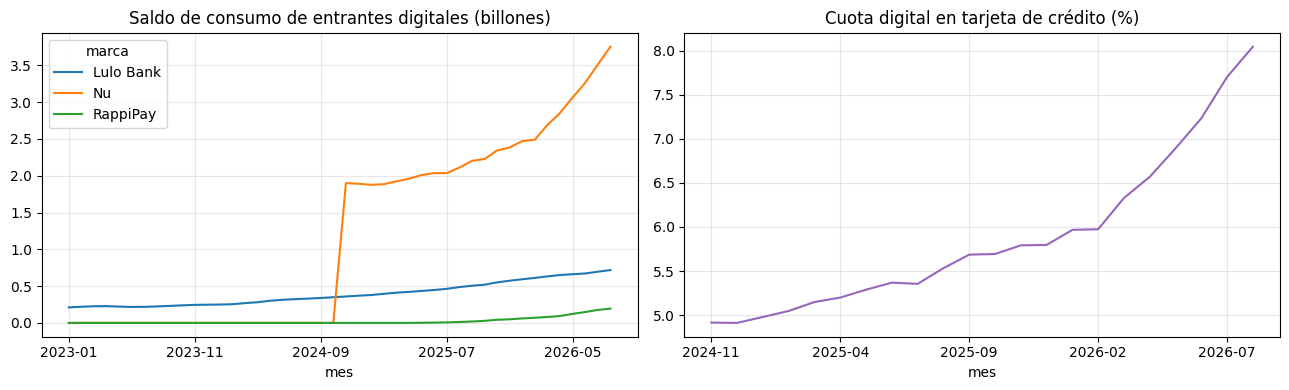

Cuota de Nu, Lulo Bank y RappiPay en tarjeta: 4.9% (2024-11) -> 8.0% (2026-08)
Participación por tipo de entidad en consumo: {'Banco': 92.8, 'Compañía de financiamiento': 5.6, 'Cooperativa financiera': 1.6, 'Instituciones oficiales especiales': 0.0}


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(mk["digitales"].loc["2023-01":] / 1e12).plot(ax=ax[0]); ax[0].set_title("Saldo de consumo de entrantes digitales (billones)")
(100 * mk["cuota_digital_tarjeta"]).plot(ax=ax[1], color="tab:purple"); ax[1].set_title("Cuota digital en tarjeta de crédito (%)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "entrantes_digitales.png", dpi=130); plt.show()
cd = mk["cuota_digital_tarjeta"]
print(f"Cuota de Nu, Lulo Bank y RappiPay en tarjeta: {cd.iloc[0]:.1%} ({cd.index[0]}) -> {cd.iloc[-1]:.1%} ({cd.index[-1]})")
print("Participación por tipo de entidad en consumo:", (100*mk["por_tipo"]).round(1).to_dict())

**Lectura.** El mercado es grande y concentrado en bancos, pero la tarjeta ya demostró que un entrante digital puede tomar
cuota rápido. La evidencia de mercado favorece la tarjeta como cuña de entrada; la libranza, la mayor bolsa de saldo,
está dominada por bancos con convenios de nómina.

## 2. Precio: ¿cuánto espacio deja el techo de usura?

In [4]:
pr = K.precios()
pr.round(2).T

producto,Tarjeta de crédito,Libre inversión,Libranza
registros,"5,309.0000","3,589.0000","1,464.0000"
tasa_ponderada,19.1200,19.2600,12.0800
tasa_p10,18.2800,12.6200,10.4900
tasa_p90,27.9100,25.6100,17.4000
usura_promedio,27.0900,27.1300,27.0800
margen_usura_mediano_ponderado,3.0300,7.5400,15.2100
monto_a_menos_de_2pp_del_techo,0.4600,0.0100,0.0000
ticket_millones,0.2300,8.7600,38.8600
desembolsos_anuales_billones,57.7800,53.1100,46.0000


In [5]:
for prod in K.PRODUCTOS:
    print(f"{prod}: margen mediano frente al techo {pr.loc[prod,'margen_usura_mediano_ponderado']:.1f} pp; "
          f"{pr.loc[prod,'monto_a_menos_de_2pp_del_techo']:.0%} del monto desembolsado a menos de 2 pp del techo; "
          f"ticket {pr.loc[prod,'ticket_millones']:.2f} millones")

Tarjeta de crédito: margen mediano frente al techo 3.0 pp; 46% del monto desembolsado a menos de 2 pp del techo; ticket 0.23 millones
Libre inversión: margen mediano frente al techo 7.5 pp; 1% del monto desembolsado a menos de 2 pp del techo; ticket 8.76 millones
Libranza: margen mediano frente al techo 15.2 pp; 0% del monto desembolsado a menos de 2 pp del techo; ticket 38.86 millones


**Lectura.** En tarjeta casi la mitad del monto se desembolsa pegada al techo: el precio no es una palanca, la usura lo fija.
En libranza el techo no muerde (15 pp de margen) porque el riesgo es bajo y la competencia es por convenios, no por tasa.
Esto cambia la estrategia: en tarjeta se compite por producto y aprobación; en libranza, por distribución.

## 3. Riesgo observado por producto (del proyecto 01)

In [6]:
rg = K.riesgo_producto()
rg

,icv90_actual,icv90_promedio,icv90_pico,mes_pico
producto,,,,
Tarjeta de crédito,0.0263,0.0346,0.0595,2021-01
Libre inversión,0.0373,0.0417,0.0771,2024-01
Libranza,0.0180,0.0158,0.0211,2024-11


## 4. Economía unitaria y la pregunta del fondeo

Estado de resultados anual por peso de saldo, en estado estable. Se comparan dos estrategias: compañía de financiamiento con
fondeo mayorista (TPM + 3 pp) y banco digital con depósitos (TPM − 1 pp, más costo de servir cuentas y más capital mínimo).

In [7]:
base = K.Supuestos()
filas = []
for est, kw in K.ESTRATEGIAS.items():
    s = replace(base, **kw)
    for prod in K.PRODUCTOS:
        filas.append({"estrategia": est, **K.economia_unitaria(prod, pr, rg, tpm, usura_hoy, s)})
U = pd.DataFrame(filas).set_index(["estrategia", "producto"])
U[["tasa_cliente", "rendimiento", "comisiones", "fondeo", "perdida", "opex", "cac", "roa", "roe"]].round(4)

tasa_cliente  \
estrategia                                   producto                           
Compañía de financiamiento, fondeo mayorista Tarjeta de crédito        0.2331   
                                             Libre inversión           0.1879   
                                             Libranza                  0.1112   
Banco digital con depósitos                  Tarjeta de crédito        0.2331   
                                             Libre inversión           0.1879   
                                             Libranza                  0.1112   

                                                                 rendimiento  \
estrategia                                   producto                          
Compañía de financiamiento, fondeo mayorista Tarjeta de crédito       0.2095   
                                             Libre inversión          0.1722   
                                             Libranza                 0.1055   
Banco digital con depósitos                  Tarjeta de crédito       0.2095   
                                             Libre inversión          0.1722   
                                             Libranza                 0.1055   

                                                                 comisiones  \
estrategia                                   producto                         
Compañía de financiamiento, fondeo mayorista Tarjeta de crédito      0.0200   
                                             Libre inversión         0.0000   
                                             Libranza                0.0000   
Banco digital con depósitos                  Tarjeta de crédito      0.0200   
                                             Libre inversión         0.0000   
                                             Libranza                0.0000   

                                                                 fondeo  \
estrategia                                   producto                     
Compañía de financiamiento, fondeo mayorista Tarjeta de crédito  0.1235   
                                             Libre inversión     0.1235   
                                             Libranza            0.1235   
Banco digital con depósitos                  Tarjeta de crédito  0.0928   
                                             Libre inversión     0.0928   
                                             Libranza            0.0928   

                                                                 perdida  \
estrategia                                   producto                      
Compañía de financiamiento, fondeo mayorista Tarjeta de crédito   0.0260   
                                             Libre inversión      0.0271   
                                             Libranza             0.0063   
Banco digital con depósitos                  Tarjeta de crédito   0.0260   
                                             Libre inversión      0.0271   
                                             Libranza             0.0063   

                                                                  opex    cac  \
estrategia                                   producto                           
Compañía de financiamiento, fondeo mayorista Tarjeta de crédito 0.0580 0.0200   
                                             Libre inversión    0.0233 0.0093   
                                             Libranza           0.0148 0.0133   
Banco digital con depósitos                  Tarjeta de crédito 0.0700 0.0200   
                                             Libre inversión    0.0267 0.0093   
                                             Libranza           0.0160 0.0133   

                                                                    roa  \
estrategia                                   producto                     
Compañía de financiamiento, fondeo mayorista Tarjeta de crédito  0.0014   
                                             Libre inversi

In [8]:
ke = base.costo_capital
mejor = U.roe.idxmax()
print(f"Costo de capital supuesto: {ke:.0%}. Mejor combinación: {mejor[1]} con {mejor[0].lower()}, ROE {U.roe.max():.1%}.")
print(f"Con fondeo mayorista ningún producto supera {U.xs(list(K.ESTRATEGIAS)[0]).roe.max():.1%} de ROE.")

Costo de capital supuesto: 18%. Mejor combinación: Tarjeta de crédito con banco digital con depósitos, ROE 10.4%.
Con fondeo mayorista ningún producto supera 1.0% de ROE.


**Primera iteración, primera conclusión.** Con una TPM de 12,25% y un techo de 28,3%, el negocio de fondeo mayorista no
existe: el diferencial entre el techo y el costo del dinero no alcanza para cubrir pérdida, operación y adquisición. Ninguna
mejora de originación compensa ese diferencial. La decisión estructural es el fondeo, no el producto.

## 5. Segunda iteración: configuración con depósitos y sin descuento de precio

El descuento de entrada de 2 pp destruye valor en tarjeta, donde el precio lo fija el techo. Se elimina, y se compite por
aprobación y experiencia.

In [9]:
dep = replace(base, **K.ESTRATEGIAS["Banco digital con depósitos"], descuento_precio_pp=0.0)
U2 = pd.DataFrame([K.economia_unitaria(p, pr, rg, tpm, usura_hoy, dep) for p in K.PRODUCTOS]).set_index("producto")
# Estrés: pérdida al pico observado del ciclo de cada producto.
estres = {p: rg.loc[p, "icv90_pico"] / rg.loc[p, "icv90_promedio"] for p in K.PRODUCTOS}
U2["roe_estres_pico"] = [K.economia_unitaria(p, pr, rg, tpm, usura_hoy, replace(dep, multiplicador_perdida=estres[p]))["roe"] for p in K.PRODUCTOS]
U2["multiplicador_pico"] = pd.Series(estres)
U2[["tasa_cliente", "roa", "roe", "multiplicador_pico", "roe_estres_pico"]].round(3)

,tasa_cliente,roa,roe,multiplicador_pico,roe_estres_pico
producto,,,,,
Tarjeta de crédito,0.2530,0.0240,0.1850,1.7180,0.0910
Libre inversión,0.2080,0.0220,0.1660,1.8480,0.0510
Libranza,0.1310,-0.0030,-0.0250,1.3340,-0.0360


## 6. Incertidumbre: qué supuesto decide el caso

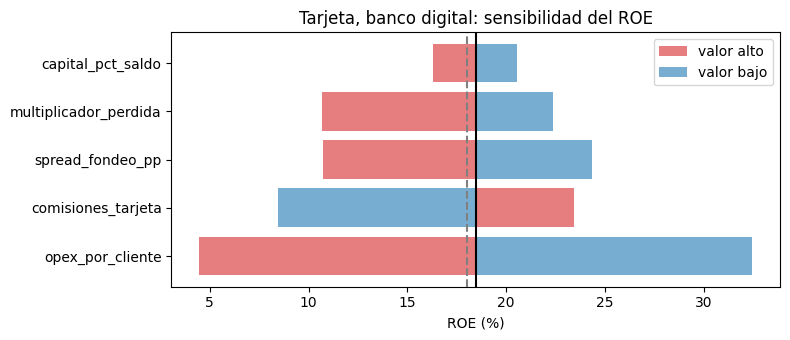

Supuesto más influyente: opex_por_cliente (rango de ROE 28.0%)


In [10]:
tor = K.tornado("Tarjeta de crédito", pr, rg, tpm, usura_hoy, dep)
fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(tor))
ax.barh(y, 100*(tor.roe_alto - tor.roe_base), left=100*tor.roe_base, color="tab:red", alpha=.6, label="valor alto")
ax.barh(y, 100*(tor.roe_bajo - tor.roe_base), left=100*tor.roe_base, color="tab:blue", alpha=.6, label="valor bajo")
ax.set_yticks(y, tor.supuesto); ax.axvline(100*tor.roe_base.iloc[0], color="k"); ax.axvline(100*ke, color="0.5", ls="--")
ax.set_xlabel("ROE (%)"); ax.set_title("Tarjeta, banco digital: sensibilidad del ROE"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "tornado_tarjeta.png", dpi=130); plt.show()
print("Supuesto más influyente:", tor.supuesto.iloc[0], f"(rango de ROE {tor.rango.iloc[0]:.1%})")

In [11]:
MC = {p: K.montecarlo(p, pr, rg, tpm, usura_hoy, dep, n=5000) for p in K.PRODUCTOS}
mc = pd.DataFrame({p: {"roe_p5": m.roe.quantile(.05), "roe_p50": m.roe.median(), "roe_p95": m.roe.quantile(.95),
                       "prob_roe_sobre_ke": (m.spread > 0).mean(), "prob_perdida": (m.roe < 0).mean()} for p, m in MC.items()}).T
mc.round(3)

,roe_p5,roe_p50,roe_p95,prob_roe_sobre_ke,prob_perdida
Tarjeta de crédito,0.0310,0.1700,0.3020,0.4470,0.0240
Libre inversión,0.0580,0.1540,0.2360,0.3050,0.0070
Libranza,-0.1060,-0.0350,0.0230,0.0000,0.8250


## 7. Escala: con costos fijos y capital mínimo, el tamaño decide

In [12]:
metas = (200_000, 400_000, 800_000, 1_200_000, 2_000_000)
E1 = K.escala("Tarjeta de crédito", pr, rg, tpm, usura_hoy, dep, metas)
E2 = K.escala("Libre inversión", pr, rg, tpm, usura_hoy, dep, metas)
tab = pd.concat({"Tarjeta": E1, "Libre inversión": E2}, axis=1)
fmt = tab.copy()
for k in ["Tarjeta", "Libre inversión"]:
    fmt[(k, "capital_aportado")] = fmt[(k, "capital_aportado")] / 1e9
    fmt[(k, "saldo_final")] = fmt[(k, "saldo_final")] / 1e12
print("capital_aportado en miles de millones; saldo_final en billones")
fmt.round(3)

capital_aportado en miles de millones; saldo_final en billones


Tarjeta                                                 \
              capital_aportado saldo_final mes_equilibrio roe_anio5 tir_anual   
clientes_meta                                                                   
200000                205.8480      0.5000            NaN   -0.0720   -0.0520   
400000                201.0630      1.0000        28.0000    0.0650    0.0220   
800000                328.1710      2.0000        25.0000    0.1190    0.1160   
1200000               457.6220      3.0000        24.0000    0.1340    0.1550   
2000000               717.2380      5.0000        23.0000    0.1450    0.1900   

               Libre inversión                                                 
              capital_aportado saldo_final mes_equilibrio roe_anio5 tir_anual  
clientes_meta                                                                  
200000                262.1110      1.8000             22    0.0900    0.1250  
400000                457.0090      3.6000             20    0.1180    0.1990  
800000                849.7570      7.2000             18    0.1300    0.2430  
1200000             1,243.6350     10.8000             18    0.1340    0.2590  
2000000             2,031.8600     18.0000             17    0.1370    0.2720

## 7b. Tercera iteración: tarjeta para adquirir, libre inversión para monetizar

La tarjeta sola no paga el costo de capital a ninguna escala razonable: el saldo por cliente es bajo frente al costo fijo y
al capital mínimo. Libre inversión rinde más por cliente, pero es el producto más cíclico. La combinación usual de los
entrantes digitales es adquirir con tarjeta y, después de 12 meses de comportamiento propio, ofrecer crédito de libre
inversión a una fracción de esos clientes. Supuestos del cruce (sensibilizables): 30% de los clientes, CAC de 50.000 pesos,
pérdida al 80% del promedio por selección con datos transaccionales, servicio compartido.

In [13]:
filas = []
for m in metas:
    filas.append({"clientes_tarjeta": m, "estrategia": "Solo tarjeta", **K.indicadores_plan(K.plan("Tarjeta de crédito", pr, rg, tpm, usura_hoy, dep, clientes_meta=m))})
    filas.append({"clientes_tarjeta": m, "estrategia": "Tarjeta + cruce libre inversión", **K.indicadores_plan(K.plan_cruzado(pr, rg, tpm, usura_hoy, dep, m))})
ESC = pd.DataFrame(filas)
piv = ESC.pivot(index="clientes_tarjeta", columns="estrategia", values="tir_anual")
print("TIR anual por escala y estrategia (salida a 1,5x patrimonio):")
piv.round(3)

TIR anual por escala y estrategia (salida a 1,5x patrimonio):


estrategia,Solo tarjeta,Tarjeta + cruce libre inversión
clientes_tarjeta,,
200000,-0.0520,0.0360
400000,0.0220,0.1560
800000,0.1160,0.2370
1200000,0.1550,0.2700
2000000,0.1900,0.3000


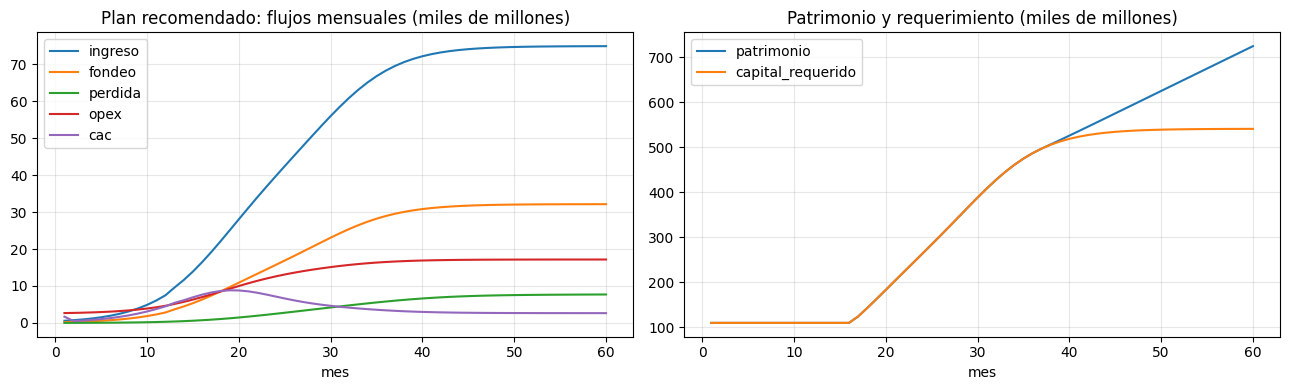

Escala mínima con TIR >= 18%: 800,000 clientes de tarjeta. Capital aportado 501 mil millones; equilibrio mensual en el mes 24; ROE año 5 18.1%; TIR 23.7%.
Solo tarjeta, misma escala: TIR 11.6%.


In [14]:
cruz = ESC[ESC.estrategia == "Tarjeta + cruce libre inversión"].set_index("clientes_tarjeta")
cubre = cruz.index[cruz.tir_anual >= ke]
meta = int(cubre[0]) if len(cubre) else int(cruz.tir_anual.idxmax())
pl = K.plan_cruzado(pr, rg, tpm, usura_hoy, dep, meta)
ind = K.indicadores_plan(pl)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
(pl.set_index("mes")[["ingreso", "fondeo", "perdida", "opex", "cac"]] / 1e9).plot(ax=ax[0]); ax[0].set_title("Plan recomendado: flujos mensuales (miles de millones)")
(pl.set_index("mes")[["patrimonio", "capital_requerido"]] / 1e9).plot(ax=ax[1]); ax[1].set_title("Patrimonio y requerimiento (miles de millones)")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "plan_recomendado.png", dpi=130); plt.show()
solo = ESC[(ESC.estrategia == "Solo tarjeta")].set_index("clientes_tarjeta")
print(f"Escala mínima con TIR >= {ke:.0%}: {meta:,} clientes de tarjeta. Capital aportado {ind['capital_aportado']/1e9:,.0f} mil millones; "
      f"equilibrio mensual en el mes {ind['mes_equilibrio']}; ROE año 5 {ind['roe_anio5']:.1%}; TIR {ind['tir_anual']:.1%}.")
print(f"Solo tarjeta, misma escala: TIR {solo.loc[meta,'tir_anual']:.1%}.")

## 8. El ciclo de tasas como opción

In [15]:
sens = K.sensibilidad_tpm("Tarjeta de crédito", pr, rg, usura_hoy, dep)
print("Techo de usura fijo en el vigente; TPM variable:")
sens.round(3)

Techo de usura fijo en el vigente; TPM variable:


,fondeo,roa,roe
tpm,,,
7.0000,0.0510,0.0510,0.3950
9.0000,0.0670,0.0410,0.3140
10.5000,0.0790,0.0330,0.2540
12.2500,0.0930,0.0240,0.1850
14.0000,0.1060,0.0150,0.1170


Como el techo se ajusta con rezago y el fondeo se reprecia rápido, un ciclo de recortes abre un margen transitorio. La
entrada se puede escalonar: lanzar con escala mínima ahora y acelerar adquisición cuando la TPM baje.

## 9. Recomendación

In [16]:
p_tc = mc.loc["Tarjeta de crédito"]
print(f'''Recomendación: lanzar como banco digital fondeado con depósitos, con tarjeta como producto de adquisición y libre
inversión cruzada a clientes con historial; escala objetivo {meta:,} clientes de tarjeta. No entrar con fondeo mayorista ni con libranza.

1. Fondeo: con fondeo mayorista el mejor ROE de estado estable es {U.xs(list(K.ESTRATEGIAS)[0]).roe.max():.1%}; con depósitos y sin descuento, {U2.roe.max():.1%}.
2. Producto: la tarjeta adquiere (ROE {U2.roe['Tarjeta de crédito']:.1%}; {U2.roe_estres_pico['Tarjeta de crédito']:.1%} con la pérdida del pico) pero sola no paga
   el capital ({solo.loc[meta,'tir_anual']:.1%} de TIR a esta escala). El cruce a libre inversión lleva la TIR a {ind['tir_anual']:.1%}.
   Libre inversión como producto de adquisición es lo más riesgoso: ROE {U2.roe_estres_pico['Libre inversión']:.1%} en el pico y la mayor beta al ciclo (proyecto 01).
3. Precio: al techo, sin descuento; el {pr.loc['Tarjeta de crédito','monto_a_menos_de_2pp_del_techo']:.0%} del monto de tarjeta ya se desembolsa a menos de 2 pp del techo.
4. Capital: {ind['capital_aportado']/1e9:,.0f} mil millones de pesos en cinco años; equilibrio mensual en el mes {ind['mes_equilibrio']}.
5. Riesgo del caso (tarjeta, Monte Carlo): probabilidad de ROE sobre el costo de capital {p_tc['prob_roe_sobre_ke']:.0%}, de ROE negativo {p_tc['prob_perdida']:.0%}.
   El supuesto que decide es {tor.supuesto.iloc[0]}: la disciplina de costo por cliente vale más que cualquier mejora de originación.
6. Tiempo: escalonar la adquisición al ciclo de recortes de la TPM; cada 175 pb menos de TPM suben el ROE de la tarjeta unos {(sens.roe.loc[10.5]-sens.roe.loc[12.25]):.0%}.''')

Recomendación: lanzar como banco digital fondeado con depósitos, con tarjeta como producto de adquisición y libre
inversión cruzada a clientes con historial; escala objetivo 800,000 clientes de tarjeta. No entrar con fondeo mayorista ni con libranza.

1. Fondeo: con fondeo mayorista el mejor ROE de estado estable es 1.0%; con depósitos y sin descuento, 18.5%.
2. Producto: la tarjeta adquiere (ROE 18.5%; 9.1% con la pérdida del pico) pero sola no paga
   el capital (11.6% de TIR a esta escala). El cruce a libre inversión lleva la TIR a 23.7%.
   Libre inversión como producto de adquisición es lo más riesgoso: ROE 5.1% en el pico y la mayor beta al ciclo (proyecto 01).
3. Precio: al techo, sin descuento; el 46% del monto de tarjeta ya se desembolsa a menos de 2 pp del techo.
4. Capital: 501 mil millones de pesos en cinco años; equilibrio mensual en el mes 24.
5. Riesgo del caso (tarjeta, Monte Carlo): probabilidad de ROE sobre el costo de capital 45%, de ROE negativo 2%.
   El supuesto q

**Límites.** Precios con margen de 2022 frente al techo; pérdida anual aproximada por el ICV90 promedio; costos, CAC, LGD y
capital mínimo son supuestos de trabajo que deben reemplazarse por cotizaciones y datos propios antes de comprometer
capital; la salida a 1,5 veces patrimonio es convencional.

In [17]:
import json
Path("resultados").mkdir(exist_ok=True)
U.to_csv("resultados/economia_unitaria_estrategias.csv"); U2.to_csv("resultados/economia_unitaria_recomendada.csv")
mc.to_csv("resultados/montecarlo_resumen.csv"); tab.to_csv("resultados/escala.csv"); pr.to_csv("resultados/precios_observados.csv")
Path("resultados/resumen.json").write_text(json.dumps({
    "tpm": tpm, "usura_vigente": usura_hoy, "roe_tarjeta_depositos": float(U2.roe["Tarjeta de crédito"]),
    "roe_max_mayorista": float(U.xs(list(K.ESTRATEGIAS)[0]).roe.max()), "plan_meta_clientes": meta,
    "tir_por_escala": {f"{k[0]}|{k[1]}": float(v) for k, v in ESC.set_index(["clientes_tarjeta", "estrategia"]).tir_anual.items()},
    "plan": {k: (float(v) if v is not None else None) for k, v in ind.items()},
    "prob_roe_sobre_ke_tarjeta": float(p_tc["prob_roe_sobre_ke"])}, indent=2, ensure_ascii=False))
print("Resultados guardados.")

Resultados guardados.
